In [18]:
import pandas as pd
import matplotlib.pyplot as plt

train=pd.read_csv("cleaned_churn_80.csv")
test=pd.read_csv("cleaned_churn_20.csv")
display(train)

print(train["Churn"].value_counts(normalize=True))
print(test["Churn"].value_counts(normalize=True))

,Unnamed: 0,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,...,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,0,KS,128,415,0,1,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,1,OH,107,415,0,1,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,2,NJ,137,415,0,0,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,3,OH,84,408,1,0,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,4,OK,75,415,1,0,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2661,2661,SC,79,415,0,0,0,134.7,98,22.90,...,68,16.12,221.4,128,9.96,11.8,5,3.19,2,0
2662,2662,AZ,192,415,0,1,36,156.2,77,26.55,...,126,18.32,279.1,83,12.56,9.9,6,2.67,2,0
2663,2663,WV,68,415,0,0,0,231.1,57,39.29,...,55,13.04,191.3,123,8.61,9.6,4,2.59,3,0
2664,2664,RI,28,510,0,0,0,180.8,109,30.74,...,58,24.55,191.9,91,8.64,14.1,6,3.81,2,0


Churn
0    0.854464
1    0.145536
Name: proportion, dtype: float64
Churn
0    0.857571
1    0.142429
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler



train = train.drop(columns="State", errors="ignore")
test=test.drop(columns="State", errors="ignore")

train = pd.get_dummies(train, columns=["Area code"], drop_first=True)
test=pd.get_dummies(test, columns=["Area code"], drop_first=True)
test = test.reindex(columns=train.columns, fill_value=0)

x_train,y_train =train.drop(columns="Churn"),train["Churn"]
x_test, y_test = test.drop(columns="Churn"), test["Churn"]

scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.fit_transform(x_test)


In [26]:
#models evaluation (accuracy,precision,recall,f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score,precision_score,f1_score,recall_score


models={
    "Logistic Regression": LogisticRegression(),
    "decision tree":DecisionTreeClassifier(),
    "random forest":RandomForestClassifier()
}

rows=[]
for name , model in models.items():
    model.fit(x_train,y_train)
    p=model.predict(x_test)
    rows.append([name,accuracy_score(y_test,p),precision_score(y_test,p),
                 recall_score(y_test,p),f1_score(y_test,p)])

result=pd.DataFrame(rows,columns=["model", "accuracy" , "precision", "recall", "f1" ])
display(result)

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.854573,0.475,0.200000,0.281481
1,decision tree,0.896552,0.625,0.684211,0.653266
2,random forest,0.952024,1.000,0.663158,0.797468


{'max_depth': 10, 'n_estimators': 200}
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       572
           1       1.00      0.64      0.78        95

    accuracy                           0.95       667
   macro avg       0.97      0.82      0.88       667
weighted avg       0.95      0.95      0.94       667



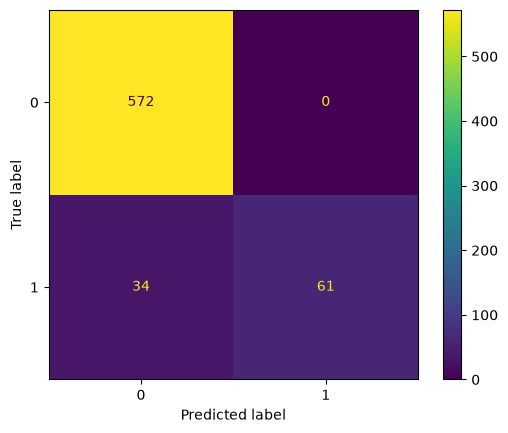

In [28]:
#Grid research

grid= GridSearchCV(
    RandomForestClassifier(),
    {"n_estimators":[100,200],"max_depth":[None,10]},
    scoring="f1",
    cv=3
)

grid.fit(x_train,y_train)
print(grid.best_params_)
print(classification_report(y_test, grid.best_estimator_.predict(x_test)))


from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,grid.best_estimator_.predict(x_test))
plt.show()